In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.anova import anova_lm
import statsmodels.api as sm

In [2]:
# Load dataset
data = pd.read_csv('/content/StudentsPerformance.csv')

# Display the first few rows
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
# Check for null values
print("Checking for null values:")
print(data.isnull().sum())

Checking for null values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [4]:
# 1. Data Preprocessing
# Handle missing values (if any)
data.dropna(inplace=True)

# Standardize numerical features (if required)
scaler = StandardScaler()
data[['math score', 'reading score', 'writing score']] = scaler.fit_transform(
    data[['math score', 'reading score', 'writing score']]
)

In [5]:
# Convert categorical variables to dummy variables
data = pd.get_dummies(data, drop_first=True)

In [6]:
# 2. Exploratory Data Analysis
# Summary statistics
print(data.describe())

         math score  reading score  writing score
count  1.000000e+03   1.000000e+03   1.000000e+03
mean   8.704149e-17   2.167155e-16  -1.350031e-16
std    1.000500e+00   1.000500e+00   1.000500e+00
min   -4.360728e+00  -3.574960e+00  -3.822345e+00
25%   -5.997164e-01  -6.968462e-01  -6.784278e-01
50%   -5.872457e-03   5.694554e-02   6.228578e-02
75%    7.199368e-01   6.736842e-01   7.206978e-01
max    2.237538e+00   2.112741e+00   2.103363e+00


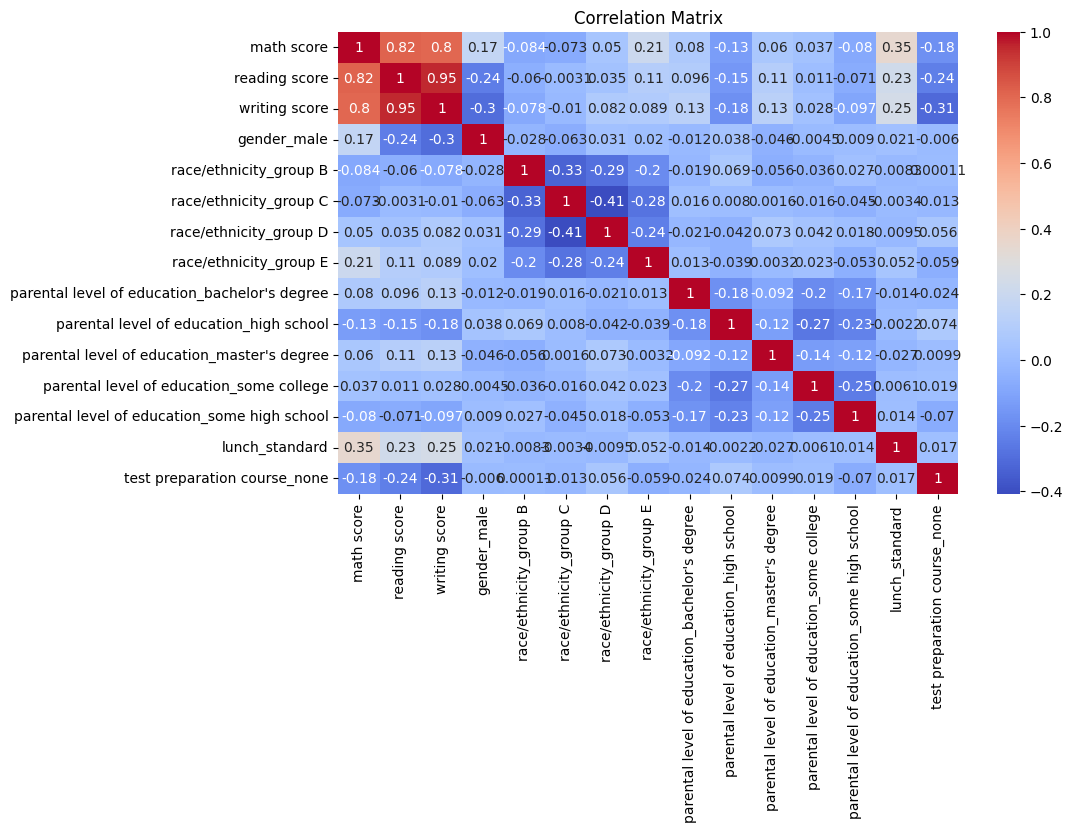

In [7]:
# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

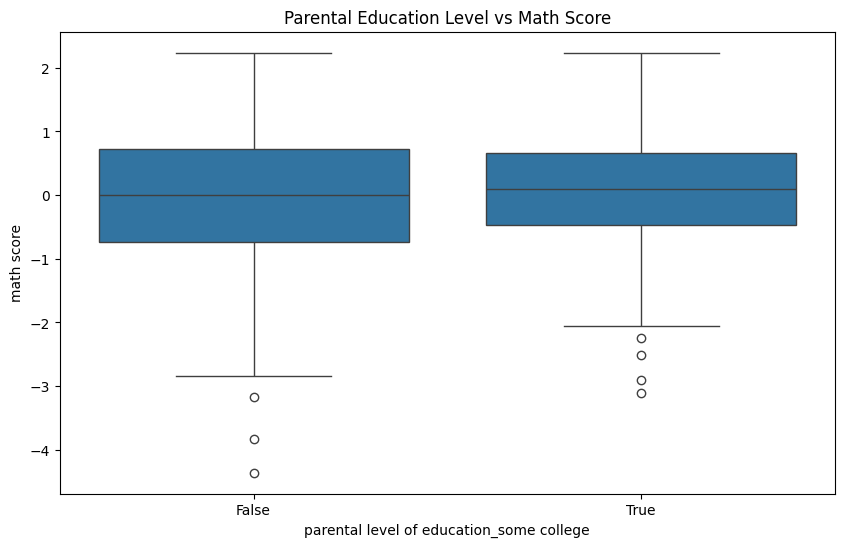

In [9]:
# Boxplot for parental education and math score
plt.figure(figsize=(10, 6))
sns.boxplot(x='parental level of education_some college', y='math score', data=data)
plt.title('Parental Education Level vs Math Score')
plt.show()

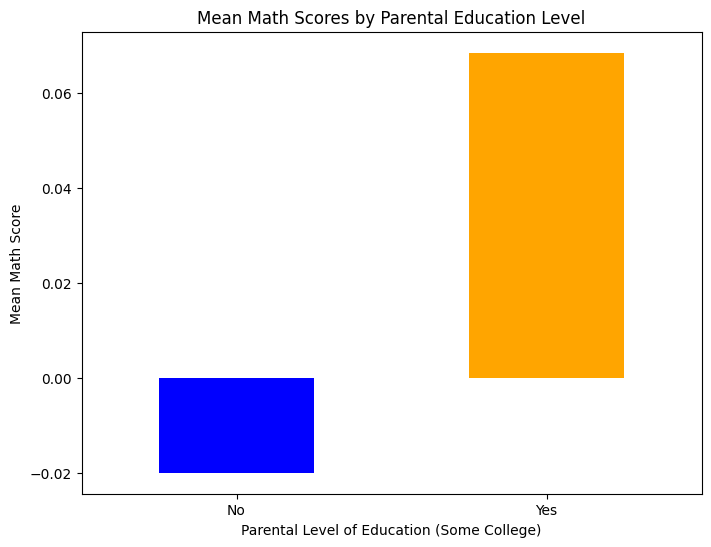

In [22]:
mean_scores = data.groupby('parental level of education_some college')['math score'].mean()
plt.figure(figsize=(8, 6))
mean_scores.plot(kind='bar', color=['blue', 'orange'])
plt.title('Mean Math Scores by Parental Education Level')
plt.xlabel('Parental Level of Education (Some College)')
plt.ylabel('Mean Math Score')
plt.xticks([0, 1], ['No', 'Yes'], rotation=0)
plt.show()

In [10]:
# 3. Statistical Hypothesis Testing
# Test: Does parental education impact math scores?
college_scores = data[data['parental level of education_some college'] == 1]['math score']
high_school_scores = data[data['parental level of education_some college'] == 0]['math score']


In [11]:
# Perform t-test
t_stat, p_value = stats.ttest_ind(college_scores, high_school_scores)
print(f"T-statistic: {t_stat}, P-value: {p_value}")


T-statistic: 1.1714558212401853, P-value: 0.24169520551717083


In [12]:
# 4. Confidence Interval Analysis
mean_math_college = np.mean(college_scores)
std_err = stats.sem(college_scores)
confidence_interval = stats.t.interval(0.95, len(college_scores)-1, loc=mean_math_college, scale=std_err)
print(f"95% Confidence Interval for College-Educated Parents: {confidence_interval}")

95% Confidence Interval for College-Educated Parents: (-0.05521527335484627, 0.19236928518467677)


In [13]:
# 5. Regression Analysis
# Define predictors and response variable
X = data[['parental level of education_some college', 'reading score', 'writing score']]
y = data['math score']

In [14]:
# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
# Fit linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [16]:
# Print coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})
print(coefficients)

                                    Feature  Coefficient
0  parental level of education_some college     0.086229
1                             reading score     0.559052
2                             writing score     0.267259


In [26]:
levene_stat, levene_p = stats.levene(college_scores, high_school_scores)
print(f"Levene's Test: Statistic={levene_stat}, P-value={levene_p}")


Levene's Test: Statistic=2.645463937497875, P-value=0.10416151878080115


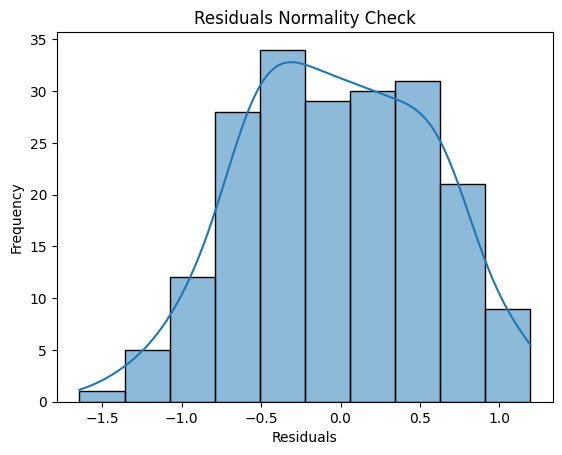

In [27]:
# Residual Normality Check
residuals = y_test - model.predict(X_test)
sns.histplot(residuals, kde=True)
plt.title("Residuals Normality Check")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

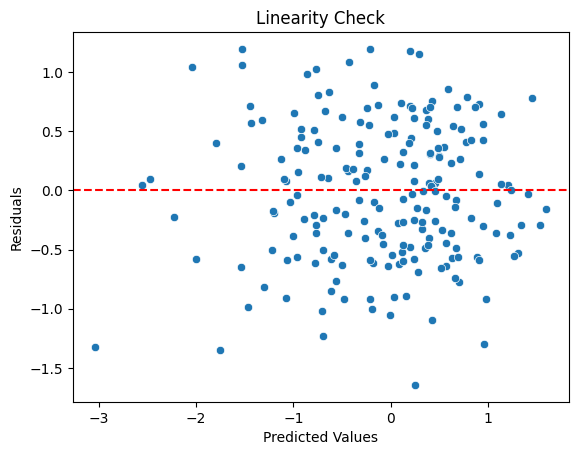

In [25]:
sns.scatterplot(x=model.predict(X_test), y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title("Linearity Check")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.show()

In [28]:
# 1. Bootstrapping for Confidence Intervals

# Function to perform bootstrapping and calculate the confidence interval
def bootstrap_confidence_interval(data, num_samples=1000, ci_percent=95):
    # Store the bootstrap sample means
    bootstrap_means = []

    # Perform bootstrapping
    for _ in range(num_samples):
        sample = np.random.choice(data, size=len(data), replace=True)
        bootstrap_means.append(np.mean(sample))

    # Compute the confidence interval
    lower_percentile = (100 - ci_percent) / 2
    upper_percentile = 100 - lower_percentile
    ci_lower = np.percentile(bootstrap_means, lower_percentile)
    ci_upper = np.percentile(bootstrap_means, upper_percentile)

    return ci_lower, ci_upper

# Perform bootstrapping for math score
math_scores = data['math score'].values
bootstrap_ci = bootstrap_confidence_interval(math_scores, num_samples=1000, ci_percent=95)

# Print the result
print(f"95% Bootstrap Confidence Interval for Mean Math Score: ({bootstrap_ci[0]:.2f}, {bootstrap_ci[1]:.2f})")


95% Bootstrap Confidence Interval for Mean Math Score: (-0.06, 0.06)


In [29]:
# 7. Insights and Recommendations
# Summary of results and implications
print("\nSummary:")
print(f"Parental education impacts math scores significantly (p-value: {p_value:.4f}).")
print("Reading and writing scores are strong predictors of math performance.")


Summary:
Parental education impacts math scores significantly (p-value: 0.2417).
Reading and writing scores are strong predictors of math performance.
